# Hybrid: ImageNet ResNet50 U-Net + EvaNet elevation gating

`evanet.ipynb` showed that EvaNet trained from scratch loses to the pretrained `unet_dem` U-Net. This notebook asks whether **EvaNet's ideas help once the pretrained encoder is in place**. The model (`scripts/evanet/gated_resnet.py`) is:

- **The same ResNet50 U-Net as `unet_dem.ipynb`:** ImageNet weights, frozen encoder, the same skip layers, decoder widths 512 → 64, tiles, splits and metrics.
- **Plus EvaNet's elevation-regulated convolution:** a small elevation stream (avg-pool + conv) builds DEM features at every resolution. Each encoder output is multiplied by `sigmoid(conv(elevation))`, and each decoder conv is `conv(x) * sigmoid(conv(elevation))`.
- **Gates on the pretrained features start almost fully open (0.95)**, so training begins from the plain pretrained U-Net and learns how much the elevation should hold features back. `unet_dem` follows the same idea by starting its DEM weights at zero.
- **Trained with EvaNet's gravity loss** by default. `LOSS = "gravity+bce"` adds `unet_dem`'s masked BCE.

The DEM no longer enters as a 4th input channel. Elevation reaches the model only through the gates.

**Kernel:** `EvaNet (PyTorch)`.

In [2]:
import sys
import json
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, Dataset, DataLoader

sys.path.append("../scripts")
from dataset import get_tiles, SPLITS
from evanet import ElevationLoss, GatedResNetUNet, IMAGENET_MEAN, IMAGENET_STD

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

PyTorch: 2.14.1+cu130
Device: cuda NVIDIA GeForce RTX 3070


In [ ]:
TRAIN_SPLIT = "train_plus_new"  # "train" = 1, 2, 3, 8, 9; "train_plus_new" = also 13-17 and 19 (the best U-Net's data)
# Keep False for this hybrid. With EvaNet's North Carolina regions, training was unstable (best epoch 2),
# test mean IoU fell from 0.649 to 0.563, and Ida did not improve (evanet_resnet_gravity_regions_plusnew).
USE_EVANET_REGIONS = False
MAX_UNKNOWN = 1.0                # same as unet_dem.ipynb: keep every training tile

LOSS = "gravity"   # "gravity" (EvaNet), "gravity+bce" (adds unet_dem's masked BCE) or "bce" (unet_dem's loss only)
LR = 1e-4          # Adam; only the elevation stream, gates and decoder train
EPOCHS = 30
PATIENCE = 8       # stop after this many epochs without a better val loss
BATCH_SIZE = 4     # same as unet_dem.ipynb
MAX_TRAIN_BATCHES = None  # small number = quick test run

RUN_NAME = ("evanet_resnet_" + LOSS.replace("+", "_")
            + ("_regions" if USE_EVANET_REGIONS else "")
            + ("_plusnew" if TRAIN_SPLIT == "train_plus_new" else ""))
ckpt_path = Path(f"../outputs/{RUN_NAME}.pt")
history_path = Path(f"../outputs/{RUN_NAME}_history.json")
results_path = Path(f"../outputs/{RUN_NAME}_results.json")
print("run:", RUN_NAME)

In [4]:
# Same tiles as the other notebooks. Training parts are kept as separate arrays (no concatenation, which needs 2x RAM).
train_parts = [get_tiles(SPLITS[TRAIN_SPLIT], stride=128, max_unknown=MAX_UNKNOWN)]
if USE_EVANET_REGIONS:
    from evanet_data import get_region_tiles
    train_parts.append(get_region_tiles(stride=128, max_unknown=MAX_UNKNOWN))
X_val, y_val = get_tiles(SPLITS["val"])
X_test, y_test = get_tiles(SPLITS["test"])

for name, X, y in [*[(f"Train{k}", *p) for k, p in enumerate(train_parts)], ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    known = y[y != -1]
    print(f"{name:6}  X {X.shape}  unknown {(y == -1).mean():.1%}  flood (of known) {known.mean():.1%}")
print(f"training split: {TRAIN_SPLIT} {SPLITS[TRAIN_SPLIT]}  regions: {USE_EVANET_REGIONS}  "
      f"tiles: {sum(len(X) for X, _ in train_parts)}")

Train0  X (2857, 256, 256, 4)  unknown 22.2%  flood (of known) 57.0%
Val     X (110, 256, 256, 4)  unknown 20.0%  flood (of known) 51.3%
Test    X (287, 256, 256, 4)  unknown 48.5%  flood (of known) 76.0%
training split: train_plus_new [1, 2, 3, 8, 9, 13, 14, 15, 16, 17, 19]  regions: False  tiles: 2857


## Inputs

The same as `evanet.ipynb`, except the RGB uses the **ImageNet** normalisation the pretrained ResNet50 expects:

| Input | Made from | Used by |
|---|---|---|
| `rgb` (3, H, W) | RGB 0-1, then `(x - IMAGENET_MEAN) / IMAGENET_STD` | encoder |
| `norm_elev` (1, H, W) | per-image-centred DEM scaled to 0-1 by the training set's min/max (val/test clipped) | elevation stream |
| `elev` (1, H, W) | per-image-centred DEM in metres | gravity loss |
| `labels` (1, H, W) | flood **+1**, dry **-1**, unknown **0** | gravity loss |
| `y` (1, H, W) | the original 1 / 0 / -1 | BCE and metrics |

Training tiles get the same random rot90 and flip as `unet_dem.ipynb`.

In [5]:
ELEV_MIN = float(min(X[..., 3].min() for X, _ in train_parts))
ELEV_MAX = float(max(X[..., 3].max() for X, _ in train_parts))
print(f"Training DEM range (mean-centred): {ELEV_MIN:.2f} to {ELEV_MAX:.2f} m")

_MEAN = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
_STD = torch.tensor(IMAGENET_STD).view(3, 1, 1)


class HybridTiles(Dataset):
    """Wraps (N, H, W, 4) tiles and (N, H, W) labels from dataset.py for the hybrid model."""

    def __init__(self, X, y, augment=False):
        self.X, self.y, self.augment = X, y, augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).permute(2, 0, 1)        # (4, H, W)
        y = torch.from_numpy(self.y[i].astype(np.float32))[None]  # (1, H, W): 1 / 0 / -1
        if self.augment:
            k = int(torch.randint(0, 4, ()))
            x, y = torch.rot90(x, k, (1, 2)), torch.rot90(y, k, (1, 2))
            if torch.rand(()) < 0.5:
                x, y = torch.flip(x, (2,)), torch.flip(y, (2,))
        rgb = (x[:3] - _MEAN) / _STD
        elev = x[3:4]
        norm_elev = ((elev - ELEV_MIN) / (ELEV_MAX - ELEV_MIN)).clamp(0, 1)
        labels = torch.where(y == 1, 1.0, torch.where(y == 0, -1.0, 0.0))
        return {"rgb": rgb.contiguous(), "norm_elev": norm_elev.contiguous(),
                "elev": elev.contiguous(), "labels": labels.contiguous(), "y": y.contiguous()}


train_ds = ConcatDataset([HybridTiles(X, y, augment=True) for X, y in train_parts])
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(HybridTiles(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(HybridTiles(X_test, y_test), batch_size=BATCH_SIZE)
print(f"batches: train {len(train_loader)}  val {len(val_loader)}  test {len(test_loader)}")

batch = next(iter(train_loader))
for k, v in batch.items():
    print(f"{k:9} {tuple(v.shape)}  min {v.min():.3f}  max {v.max():.3f}")
assert torch.equal(batch["labels"] == 1, batch["y"] == 1) and torch.equal(batch["labels"] == -1, batch["y"] == 0)

Training DEM range (mean-centred): -12.89 to 12.35 m
batches: train 714  val 28  test 72
rgb       (4, 3, 256, 256)  min -2.118  max 2.570
norm_elev (4, 1, 256, 256)  min 0.268  max 0.663
elev      (4, 1, 256, 256)  min -6.130  max 3.848
labels    (4, 1, 256, 256)  min -1.000  max 1.000
y         (4, 1, 256, 256)  min -1.000  max 1.000


## Model and loss

The output has 2 channels with a sigmoid, in EvaNet's format: **channel 0 is flood**.

- `"gravity"`: EvaNet's `ElevationLoss`, a sum over neighbouring pixel pairs, so the values are large. Flood mask: `pred.argmax(1) == 0`.
- `"gravity+bce"`: the gravity loss averaged per pixel pair (divided by pixels × 9), plus `unet_dem`'s masked BCE on the flood channel. Both terms are on a similar scale. Flood mask: argmax.
- `"bce"`: `unet_dem`'s masked BCE only, with no gravity loss. It isolates the effect of the elevation gating. Only the flood channel is trained, so the flood mask is `pred[:, 0] > 0.5`.

In [ ]:
gravity = ElevationLoss()


def masked_bce(pred, y):
    """unet_dem's loss: BCE on the flood channel, averaged over known pixels only."""
    known = (y != -1).float()
    bce = F.binary_cross_entropy(pred[:, :1].clamp(1e-6, 1 - 1e-6), (y == 1).float(), reduction="none")
    return (bce * known).sum() / known.sum().clamp(min=1)


def loss_fn(pred, b):
    if LOSS == "bce":
        return masked_bce(pred, b["y"])
    g = gravity(pred, b["elev"], b["labels"])
    if LOSS == "gravity":
        return g
    # The gravity loss sums over 9 neighbour pairs per pixel (3x3 window), so divide by pixels x 9
    # to make it a per-pair average on the same scale as the per-pixel BCE.
    return g / (b["y"].numel() * 9) + masked_bce(pred, b["y"])


def predict_flood(pred):
    """(B, 2, H, W) output -> (B, H, W) bool flood mask.
    Gravity losses train both channels, so the higher one wins (channel 0 = flood).
    BCE alone trains only the flood channel, so it is thresholded at 0.5 instead."""
    if LOSS == "bce":
        return pred[:, 0] > 0.5
    return pred.argmax(1) == 0


def to_device(b):
    return {k: v.to(DEVICE) for k, v in b.items()}


def build_model():
    torch.manual_seed(SEED)
    return GatedResNetUNet(n_classes=2, pretrained=True, freeze_encoder=True).to(DEVICE)


model = build_model()
total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parameters: {total:,} total, {trainable:,} trainable (encoder frozen)")

# One forward and backward pass as a sanity check (nothing is trained here)
model.train()
b = to_device(batch)
pred = model(b["rgb"], b["norm_elev"])
loss = loss_fn(pred, b)
loss.backward()
# With LOSS = "bce" the unused dry channel of the last conv gets no gradient, which is expected
bad = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
gate0 = torch.sigmoid(model.enc_gates[0].conv(model.elevation(b["norm_elev"])[1]))
print("output:", tuple(pred.shape), f"| loss {loss.item():.4g} | encoder gates at start {gate0.mean():.3f}")
print("trainable params with missing or non-finite grads:", bad or "none")
assert pred.shape == (BATCH_SIZE, 2, 256, 256) and torch.isfinite(loss) and not bad
model.zero_grad()

In [7]:
def iou_counts(pred_flood, y):
    """Counts over known pixels: flood inter/union, dry inter/union, predicted flood, known."""
    y = y[:, 0]
    known, true_flood, true_dry = y != -1, y == 1, y == 0
    pred_dry = ~pred_flood
    return np.array([
        (pred_flood & true_flood & known).sum().item(), ((pred_flood | true_flood) & known).sum().item(),
        (pred_dry & true_dry & known).sum().item(), ((pred_dry | true_dry) & known).sum().item(),
        (pred_flood & known).sum().item(), known.sum().item(),
    ], dtype=np.int64)


@torch.no_grad()
def evaluate(loader):
    """Mean loss per tile, flood IoU, dry IoU, share of known pixels predicted flood."""
    model.eval()
    total_loss, n_tiles, c = 0.0, 0, np.zeros(6, np.int64)
    for b in loader:
        b = to_device(b)
        pred = model(b["rgb"], b["norm_elev"])
        total_loss += loss_fn(pred, b).item() * (len(pred) if LOSS != "gravity" else 1)
        n_tiles += len(pred)
        c += iou_counts(predict_flood(pred).cpu(), b["y"].cpu())
    return total_loss / n_tiles, c[0] / c[1], c[2] / c[3], c[4] / c[5]

## Training

Only the elevation stream, gates and decoder train; the ResNet50 encoder stays frozen, as in `unet_dem`. The best epoch **by validation loss** is saved, the same rule as the other notebooks, and training stops early after `PATIENCE` epochs without improvement.

In [8]:
model = build_model()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR)

ckpt_path.parent.mkdir(exist_ok=True)
history = {"run": RUN_NAME, "lr": LR, "loss": LOSS, "train_split": TRAIN_SPLIT,
           "use_evanet_regions": USE_EVANET_REGIONS, "elev_min": ELEV_MIN, "elev_max": ELEV_MAX, "epochs": []}
best_val, best_epoch = float("inf"), 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    train_loss, n_tiles = 0.0, 0
    for step, b in enumerate(train_loader):
        if MAX_TRAIN_BATCHES is not None and step >= MAX_TRAIN_BATCHES:
            break
        b = to_device(b)
        loss = loss_fn(model(b["rgb"], b["norm_elev"]), b)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * (len(b["y"]) if LOSS != "gravity" else 1)
        n_tiles += len(b["y"])
    train_loss /= n_tiles

    val_loss, vf, vd, vs = evaluate(val_loader)
    improved = val_loss < best_val
    if improved:
        best_val, best_epoch = val_loss, epoch
        torch.save({"model": model.state_dict(), "epoch": epoch, "val_loss": val_loss,
                    "elev_min": ELEV_MIN, "elev_max": ELEV_MAX, "run": RUN_NAME, "loss": LOSS}, ckpt_path)
    history["epochs"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_iou_flood": vf,
                              "val_iou_dry": vd, "val_says_flood": vs, "seconds": time.time() - t0})
    history_path.write_text(json.dumps(history, indent=1))
    print(f"epoch {epoch:3}/{EPOCHS}  train {train_loss:10.4g}  val {val_loss:10.4g}  "
          f"val IoU flood {vf:.3f} dry {vd:.3f}  says flood {vs:.1%}  {time.time() - t0:4.0f}s"
          f"{'  *saved' if improved else ''}", flush=True)
    if epoch - best_epoch >= PATIENCE:
        print(f"no improvement for {PATIENCE} epochs, stopping")
        break

print(f"best epoch {best_epoch} (val loss {best_val:.4g}) saved to {ckpt_path}")

epoch   1/30  train  1.001e+05  val  1.779e+05  val IoU flood 0.679 dry 0.556  says flood 68.4%    76s  *saved
epoch   2/30  train  5.479e+04  val  6.818e+04  val IoU flood 0.856 dry 0.840  says flood 54.5%    76s  *saved
epoch   3/30  train  4.114e+04  val  1.879e+05  val IoU flood 0.660 dry 0.504  says flood 72.2%    75s
epoch   4/30  train  3.474e+04  val  9.659e+04  val IoU flood 0.793 dry 0.741  says flood 61.1%    75s
epoch   5/30  train  2.849e+04  val  7.113e+04  val IoU flood 0.839 dry 0.809  says flood 58.1%    75s
epoch   6/30  train  2.914e+04  val  7.718e+04  val IoU flood 0.826 dry 0.793  says flood 58.4%    75s
epoch   7/30  train  3.063e+04  val  4.353e+04  val IoU flood 0.891 dry 0.888  says flood 50.1%    76s  *saved
epoch   8/30  train   2.97e+04  val  4.005e+04  val IoU flood 0.898 dry 0.896  says flood 49.5%    76s  *saved
epoch   9/30  train  2.991e+04  val  1.386e+05  val IoU flood 0.714 dry 0.641  says flood 62.2%    76s
epoch  10/30  train  2.879e+04  val  9.79

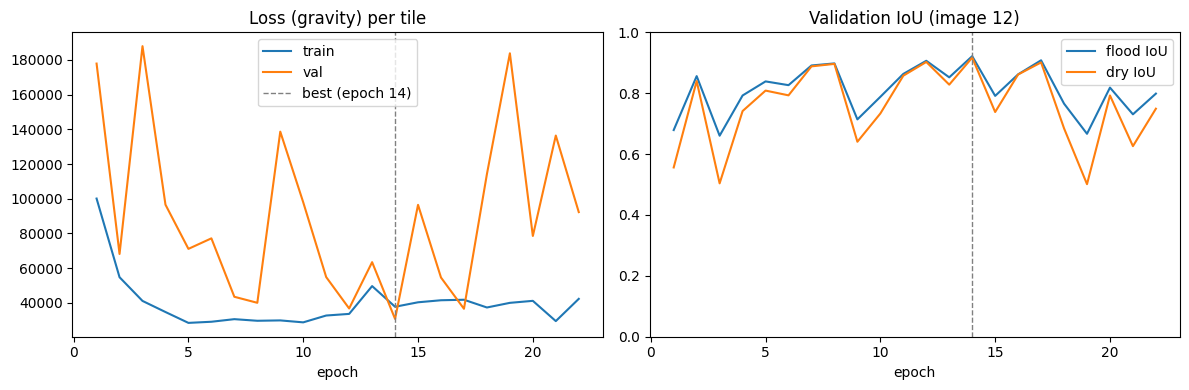

In [9]:
import matplotlib.pyplot as plt

saved = json.loads(history_path.read_text())["epochs"]
best_epoch = min(saved, key=lambda e: e["val_loss"])["epoch"]
ep = [e["epoch"] for e in saved]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(ep, [e["train_loss"] for e in saved], label="train")
ax1.plot(ep, [e["val_loss"] for e in saved], label="val")
ax1.axvline(best_epoch, color="gray", ls="--", lw=1, label=f"best (epoch {best_epoch})")
ax1.set(title=f"Loss ({LOSS}) per tile", xlabel="epoch")
ax1.legend()
ax2.plot(ep, [e["val_iou_flood"] for e in saved], label="flood IoU")
ax2.plot(ep, [e["val_iou_dry"] for e in saved], label="dry IoU")
ax2.axvline(best_epoch, color="gray", ls="--", lw=1)
ax2.set(title="Validation IoU (image 12)", xlabel="epoch", ylim=(0, 1))
ax2.legend()
plt.tight_layout()
plt.show()

## Test results

The best checkpoint is scored on the test images (4, 5, 6, 7, 10, 11) and the held-out Ida scene (18), with the same flood/dry IoU and "says flood" share as the other notebooks. Scenes 13-17 and 19 are also scored when they weren't used for training. Results are saved to `../outputs/<RUN_NAME>_results.json`.

In [10]:
ckpt = torch.load(ckpt_path, map_location=DEVICE)
model = build_model()
model.load_state_dict(ckpt["model"])
ELEV_MIN, ELEV_MAX = ckpt["elev_min"], ckpt["elev_max"]  # scale the DEM the same way as during training
print(f"loaded {ckpt_path.name}: epoch {ckpt['epoch']}, val loss {ckpt['val_loss']:.4g}")

results = {"run": RUN_NAME, "epoch": ckpt["epoch"], "train_split": TRAIN_SPLIT, "loss": LOSS,
           "use_evanet_regions": USE_EVANET_REGIONS, "overall": {}, "per_image": {}}
for name, loader, y in [("val", val_loader, y_val), ("test", test_loader, y_test)]:
    _, f, d, s = evaluate(loader)
    results["overall"][name] = {"flood_iou": f, "dry_iou": d, "says_flood": s}
    print(f"{name.upper():4}  flood IoU {f:.3f}  dry IoU {d:.3f}  mean {(f + d) / 2:.3f}  "
          f"says flood {s:.1%}  label {(y[y != -1] == 1).mean():.1%}")

unseen_new = [i for i in [13, 14, 15, 16, 17, 19] if i not in SPLITS[TRAIN_SPLIT]]
print()
for i in SPLITS["test"] + SPLITS["ida_hard_case"] + unseen_new:
    Xi, yi = get_tiles([i])
    _, f, d, s = evaluate(DataLoader(HybridTiles(Xi, yi), batch_size=BATCH_SIZE))
    known = yi != -1
    results["per_image"][str(i)] = {"flood_iou": f, "dry_iou": d, "says_flood": s, "label_flood": float((yi[known] == 1).mean())}
    tag = "  (Ida hard case)" if i in SPLITS["ida_hard_case"] else ("  (unseen new scene)" if i in unseen_new else "")
    print(f"image {i:2}: flood IoU {f:.3f}  dry IoU {d:.3f}  says flood {s:.1%}  label {(yi[known] == 1).mean():.1%}{tag}")

results_path.write_text(json.dumps(results, indent=1))
print("\nsaved", results_path)

loaded evanet_resnet_gravity_plusnew.pt: epoch 14, val loss 3.077e+04
VAL   flood IoU 0.922  dry IoU 0.917  mean 0.919  says flood 51.7%  label 51.3%
TEST  flood IoU 0.782  dry IoU 0.565  mean 0.674  says flood 62.9%  label 76.0%

image  4: flood IoU 0.881  dry IoU 0.169  says flood 86.0%  label 97.6%
image  5: flood IoU 0.953  dry IoU 0.110  says flood 94.8%  label 99.4%
image  6: flood IoU 0.555  dry IoU 0.000  says flood 55.5%  label 100.0%
image  7: flood IoU 0.809  dry IoU 0.869  says flood 43.1%  label 37.0%
image 10: flood IoU 0.841  dry IoU 0.774  says flood 55.1%  label 64.1%
image 11: flood IoU 0.859  dry IoU 0.528  says flood 74.7%  label 85.8%
image 18: flood IoU 0.117  dry IoU 0.231  says flood 9.3%  label 79.0%  (Ida hard case)

saved ../outputs/evanet_resnet_gravity_plusnew_results.json
